# 03 · Interim crossing table (channel-level topics)

First pass at RQ1 and RQ2 for the mid-term. **Topics here are channel-level proxies**: each forward gets the
dataset's LDA topic of its **source** channel (`PROJECT_CONTEXT.md` §5). They will be replaced by
message-level LSRTopic topics in notebook 04, and this notebook will then be re-run.

**Scope:** English–English **text** forwards (7,731,006), i.e. the future LSRTopic corpus. Media forwards
get no topic and are left out (D18). Edge direction is content flow, `src -> dest`: written in `src`,
reposted in `dest`.

**Measures**
| | Population | Event | Boundary |
|---|---|---|---|
| RQ1 | all forwards in scope | source and destination in different communities | Leiden communities, notebook 02 |
| RQ2 | conspiracy-sourced forwards | destination not conspiracy | published conspiracy label |
| RQ2, reverse | non-conspiracy-sourced forwards | destination conspiracy | published conspiracy label |

**Inference** (D15, D18): permutation null (topic labels permuted across the population's forwards,
B = 1,000, seed 42, two-sided p, Benjamini–Hochberg), plus a 95% bootstrap interval over **source
channels**. A topic is called *more* or *less* permeable than average only if q < 0.05 **and** the
bootstrap interval of its excess over the overall rate excludes 0. Under channel-level topics, every
forward of a source has the same topic, so the bootstrap interval is the honest uncertainty. The
permutation p-values mostly reflect the huge number of forwards.

Also: source × destination channel topics (D17), a description of where content goes.

In [1]:
import json, sys
from pathlib import Path

import igraph as ig
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("src").resolve()))
from tgperm import config as cfg, data, plots, crossing
from tgperm.describe import mix

plots.use_style()
OUT = cfg.RESULTS / "03"   # this notebook's tables and figures
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 60, "display.width", 200)
B, SEED = 1000, cfg.SEED

con = data.connect()
channels = data.channel_table(con).set_index("channel_id")
community = pd.read_parquet(cfg.DERIVED / "communities.parquet").set_index("channel_id").community
fw = pd.read_parquet(data.build_en_text_windows(con))
assert fw.n_text.sum() == 7_731_006 and len(fw) == 711_022, (fw.n_text.sum(), len(fw))

topics = sorted(channels.ch_topic.dropna().unique())
tcode = {t: i for i, t in enumerate(topics)}
fw = fw.assign(
    src_topic=fw.src_id.map(channels.ch_topic), dest_topic=fw.dest_id.map(channels.ch_topic),
    src_consp=fw.src_id.map(channels.conspiracy), dest_consp=fw.dest_id.map(channels.conspiracy),
    cross=fw.src_id.map(community).to_numpy() != fw.dest_id.map(community).to_numpy())
fw["topic"] = fw.src_topic.map(tcode)
assert fw[["src_topic", "dest_topic"]].notna().all().all()
print(f"{fw.n_text.sum():,} English–English text forwards on {len(fw):,} edges, "
      f"from {fw.src_id.nunique():,} source channels to {fw.dest_id.nunique():,} destination channels")

7,731,006 English–English text forwards on 711,022 edges, from 16,896 source channels to 13,661 destination channels


## 1 · Source × destination channel topics

Where content goes, by the channel topic of the source and of the destination (D17). **Figure 1** colour =
lift: observed forwards / forwards expected if source and destination topics were independent, on a log
scale (red = more than expected, blue = fewer). Numbers = row share: of the forwards written in channels
of the row topic, the share reposted in channels of the column topic (shown when ≥ 5%). Edge direction:
content flow, `src -> dest`.

In [2]:
M = fw.pivot_table(index="src_topic", columns="dest_topic", values="n_text", aggfunc="sum", fill_value=0)
M = M.reindex(index=topics, columns=topics, fill_value=0)
N = M.to_numpy().sum()
row, col = M.sum(axis=1).to_numpy(), M.sum(axis=0).to_numpy()
lift = M / np.outer(row, col) * N
share = M.div(row, axis=0)

e, a, b = M.to_numpy() / N, row / N, col / N
same, same_exp = np.trace(e), (a * b).sum()
r = (same - same_exp) / (1 - same_exp)
print(f"forwards between channels of the same topic: {same:.1%} (expected if independent: {same_exp:.1%}); "
      f"categorical assortativity r = {r:.3f}")

flow = pd.DataFrame({"forwards_written": row.astype(int), "forwards_reposted": col.astype(int),
                     "stays_in_topic": np.diag(share), "main_other_destination": [
                         f"{share.loc[t].drop(t).idxmax()} ({share.loc[t].drop(t).max():.0%})" for t in topics]},
                    index=pd.Index(topics, name="channel topic"))
flow.style.format({"forwards_written": "{:,}", "forwards_reposted": "{:,}", "stays_in_topic": "{:.0%}"})

forwards between channels of the same topic: 70.6% (expected if independent: 23.0%); categorical assortativity r = 0.618


,forwards_written,forwards_reposted,stays_in_topic,main_other_destination
channel topic,,,,
Carding,"462,805","693,156",81%,Videogame modding (15%)
Covid,"745,470","802,779",60%,US news (29%)
Crypto,"86,246","47,594",41%,US news (21%)
Entertainment,"156,203","101,807",53%,Porn (18%)
Extremists and radicals,"342,898","405,921",50%,US news (21%)
Indian edu,"156,543","152,601",95%,Religion (2%)
Porn,"339,158","406,995",95%,Carding (1%)
Religion,"564,992","591,947",51%,US news (20%)
Social,"20,503","5,081",16%,Porn (54%)


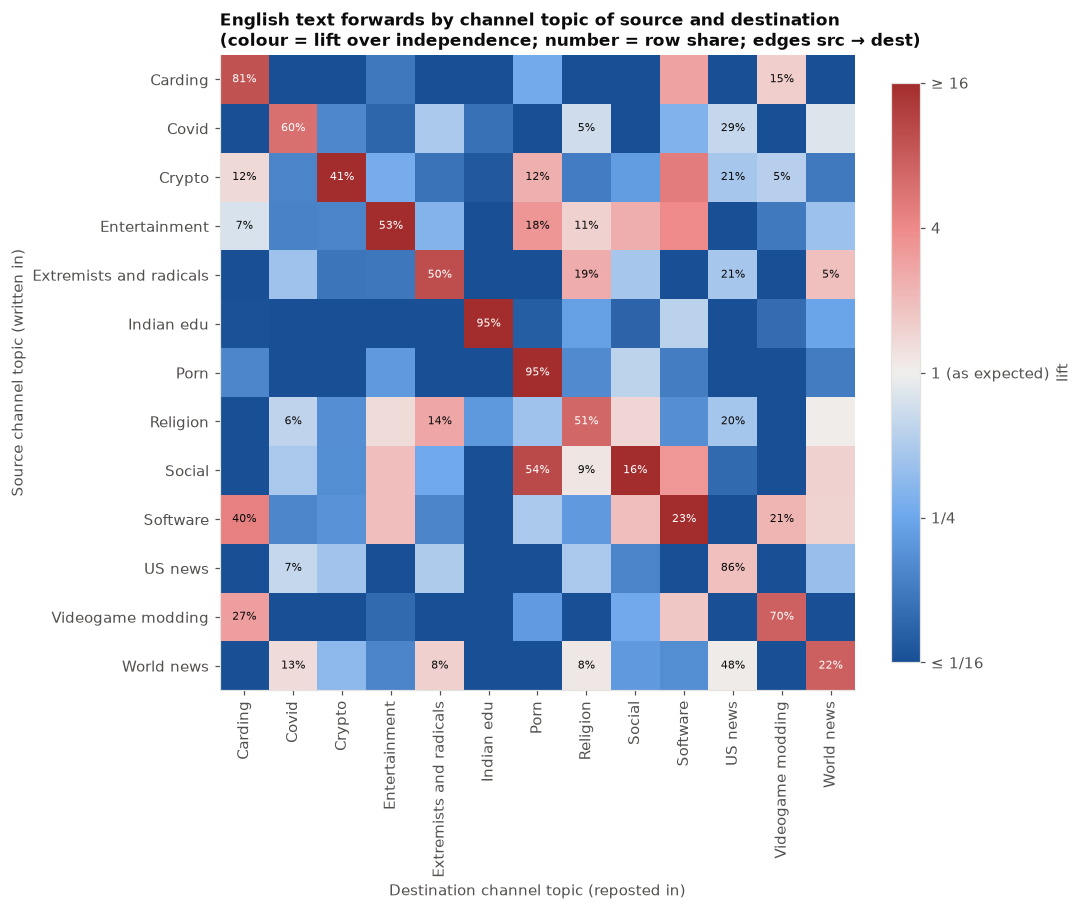

In [3]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
div = LinearSegmentedColormap.from_list("div", ["#184f95", "#6da7ec", "#f0efec", "#ee8a8a", "#a32d2d"])
L = np.log2(lift.to_numpy().clip(1 / 16, 16))
fig, ax = plt.subplots(figsize=(8.5, 7.5))
im = ax.imshow(L, cmap=div, norm=TwoSlopeNorm(0, -4, 4))
ax.set_xticks(range(len(topics)), topics, rotation=90); ax.set_yticks(range(len(topics)), topics); ax.grid(False)
for i in range(len(topics)):
    for j in range(len(topics)):
        if share.iat[i, j] >= 0.05:
            ax.text(j, i, f"{share.iat[i, j]:.0%}", ha="center", va="center", fontsize=7,
                    color="white" if abs(L[i, j]) > 2.5 else plots.INK)
ax.set_xlabel("Destination channel topic (reposted in)"); ax.set_ylabel("Source channel topic (written in)")
ax.set_title("English text forwards by channel topic of source and destination\n"
             "(colour = lift over independence; number = row share; edges src → dest)", loc="left")
cb = fig.colorbar(im, ax=ax, fraction=0.04, ticks=[-4, -2, 0, 2, 4])
cb.ax.set_yticklabels(["≤ 1/16", "1/4", "1 (as expected)", "4", "≥ 16"]); cb.set_label("lift")
plots.savefig(fig, "03_fig1_topic_flow", OUT)
plt.show()

**Channel-topic change × community crossing.** Do forwards that cross a community boundary also go to a
channel of a different topic?

In [4]:
fw["same_topic"] = fw.src_topic == fw.dest_topic
x = fw.groupby(["cross", "same_topic"]).n_text.sum().unstack()
x.index = x.index.map({False: "within community", True: "across communities"})
x.columns = x.columns.map({False: "different channel topic", True: "same channel topic"})
print((x.div(x.sum(axis=1), axis=0)).map("{:.1%}".format).assign(forwards=x.sum(axis=1).map("{:,}".format)).to_string())

same_topic         different channel topic same channel topic   forwards
cross                                                                   
within community                     28.1%              71.9%  7,344,031
across communities                   54.0%              46.0%    386,975


## 2 · RQ1 — Which (source-channel) topics cross community boundaries?

Crossing rate per topic, its excess over the overall rate (percentage points) with the bootstrap 95%
interval, the permutation-null band, and the verdict (D15). `edge_rate` = share of the topic's edges that
cross (secondary, D18).

In the figures, each label gives the topic's forwards and the number of source channels behind them
(`fwd · ch.`). Rows with fewer than 30 source channels are drawn in grey: their bootstrap intervals are
very wide, and most likely they reflect a few mislabeled channels. This is display only; no topic is
removed from the tables.

In [5]:
def rows_for(n_col, pop, event):
    d = fw[pop & (fw[n_col] > 0)]
    return pd.DataFrame({"topic": d.topic.to_numpy(), "source": d.src_id.to_numpy(),
                         "n": d[n_col].to_numpy(), "x": d[n_col].to_numpy() * event[pop & (fw[n_col] > 0)].to_numpy()}), d

def edge_rate(d, event):
    return d.assign(ev=event.loc[d.index]).groupby("topic").ev.mean().reindex(range(len(topics))).to_numpy()

def show(tab):
    cols = ["topic", "forwards", "sources", "rate", "excess_pp", "excess_low_pp", "excess_high_pp",
            "null_rate_low", "null_rate_high", "q", "verdict"] + (["edge_rate"] if "edge_rate" in tab else [])
    return tab[cols].sort_values("rate", ascending=False).style.format({
        "forwards": "{:,}", "sources": "{:,}", "rate": "{:.1%}", "excess_pp": "{:+.1f}", "excess_low_pp": "{:+.1f}",
        "excess_high_pp": "{:+.1f}", "null_rate_low": "{:.1%}", "null_rate_high": "{:.1%}", "q": "{:.3f}",
        "edge_rate": "{:.1%}"}).hide(axis="index")

everyone = pd.Series(True, index=fw.index)
rows, d = rows_for("n_text", everyone, fw.cross)
rq1 = crossing.topic_table(rows, topics, B, SEED)
rq1["edge_rate"] = edge_rate(d, fw.cross)
rq1.to_csv(OUT / "03_rq1_topics.csv", index=False)
print(f"overall crossing rate: {rq1.attrs['overall_rate']:.2%} ({rq1.attrs['events']:,} of {rq1.attrs['population']:,} forwards)")
show(rq1)

overall crossing rate: 5.01% (386,975 of 7,731,006 forwards)


topic,forwards,sources,rate,excess_pp,excess_low_pp,excess_high_pp,null_rate_low,null_rate_high,q,verdict,edge_rate
World news,"563,730",855,13.8%,+8.8,+5.6,+12.3,5.0%,5.1%,0.001,more,22.1%
Covid,"745,470","1,543",9.9%,+4.9,+2.7,+7.3,5.0%,5.1%,0.001,more,15.8%
Religion,"564,992","4,046",5.2%,+0.2,-0.9,+1.3,4.9%,5.1%,0.001,not distinguishable,10.0%
US news,"3,262,191","2,749",5.2%,+0.2,-0.7,+1.1,5.0%,5.0%,0.001,not distinguishable,14.4%
Entertainment,"156,203","1,029",4.7%,-0.3,-2.6,+3.1,4.9%,5.1%,0.001,not distinguishable,17.6%
Crypto,"86,246",471,3.7%,-1.3,-3.6,+2.6,4.9%,5.2%,0.001,not distinguishable,9.5%
Extremists and radicals,"342,898",888,3.5%,-1.5,-2.7,-0.0,4.9%,5.1%,0.001,less,7.5%
Software,"120,129",712,2.8%,-2.2,-4.2,+1.6,4.9%,5.1%,0.001,not distinguishable,17.5%
Social,"20,503",153,2.3%,-2.7,-4.6,+0.9,4.7%,5.3%,0.001,not distinguishable,10.1%
Porn,"339,158",674,1.5%,-3.5,-4.8,-2.1,4.9%,5.1%,0.001,less,4.9%


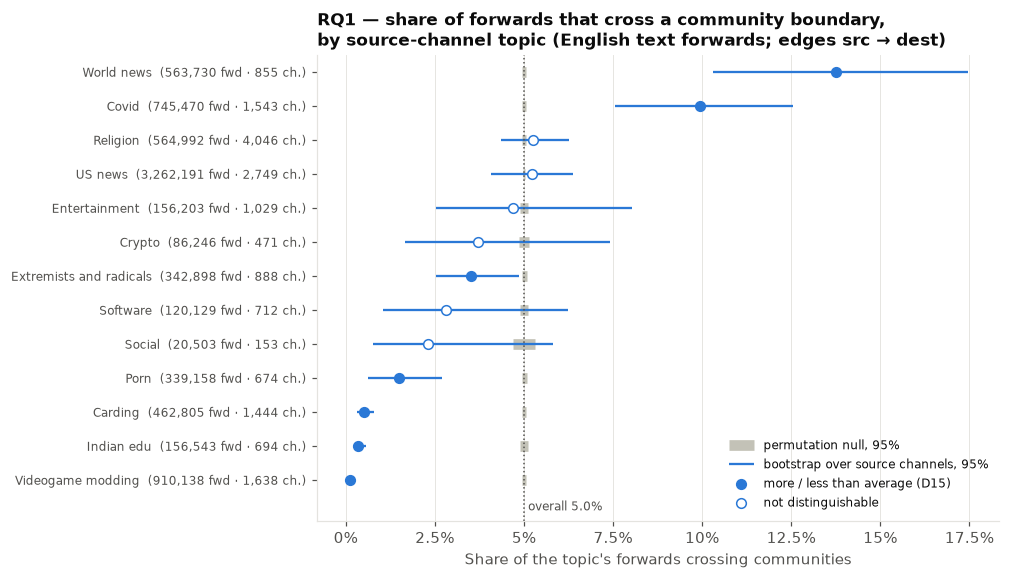

In [6]:
MIN_SOURCES_DISPLAY = 30   # display only: rows with fewer source channels are greyed out (DECISIONS, 2026-10-16)
LOW = "#a3a29d"

def dotplot(ax, tab, title, xlabel):
    t = tab.sort_values("rate").reset_index(drop=True)
    y = np.arange(len(t))
    sig = (t.verdict != "not distinguishable").to_numpy()
    low = (t.sources < MIN_SOURCES_DISPLAY).to_numpy()
    ok = ~low
    ax.hlines(y, t.null_rate_low, t.null_rate_high, color="#c3c2b7", lw=7, label="permutation null, 95%")
    ax.hlines(y[ok], t.rate_low[ok], t.rate_high[ok], color=plots.SERIES[0], lw=1.5, label="bootstrap over source channels, 95%")
    ax.hlines(y[low], t.rate_low[low], t.rate_high[low], color=LOW, lw=1.5)
    ax.scatter(t.rate[sig & ok], y[sig & ok], color=plots.SERIES[0], s=40, zorder=3, label="more / less than average (D15)")
    ax.scatter(t.rate[~sig & ok], y[~sig & ok], facecolor="white", edgecolor=plots.SERIES[0], s=40, zorder=3,
               label="not distinguishable")
    ax.scatter(t.rate[sig & low], y[sig & low], color=LOW, s=40, zorder=3)
    ax.scatter(t.rate[~sig & low], y[~sig & low], facecolor="white", edgecolor=LOW, s=40, zorder=3)
    if low.any():
        ax.scatter([], [], color=LOW, s=40, label=f"fewer than {MIN_SOURCES_DISPLAY} source channels: too few to interpret")
    ax.axvline(tab.attrs["overall_rate"], ls=":", color=plots.INK_2, lw=1)
    ax.text(tab.attrs["overall_rate"], -0.9, f" overall {tab.attrs['overall_rate']:.1%}", fontsize=8, color=plots.INK_2)
    ax.set_ylim(-1.2, len(t) - 0.5)
    ax.set_yticks(y, [f"{a}  ({n:,} fwd · {k:,} ch.)" for a, n, k in zip(t.topic, t.forwards, t.sources)], fontsize=8)
    for lbl, is_low in zip(ax.get_yticklabels(), low):
        if is_low:
            lbl.set_color(LOW)
    ax.xaxis.set_major_formatter(lambda v, _: f"{100 * v:g}%"); ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel); ax.set_title(title, loc="left")

fig, ax = plt.subplots(figsize=(8, 5.5))
dotplot(ax, rq1, "RQ1 — share of forwards that cross a community boundary,\nby source-channel topic "
        "(English text forwards; edges src → dest)", "Share of the topic's forwards crossing communities")
ax.legend(loc="lower right", fontsize=8)
plots.savefig(fig, "03_fig2_rq1", OUT)
plt.show()

## 3 · RQ2 — Through which topics does conspiracy content reach non-conspiracy channels?

Population: forwards written in conspiracy-labeled channels; event: reposted in a non-conspiracy channel.
Reverse (secondary): forwards written in non-conspiracy channels that are reposted in conspiracy channels,
i.e. what conspiracy channels import. Both populations are **all** English–English text forwards of
that kind, inside and across communities: RQ2 does not use communities. Grey rows: fewer than 30 source
channels (display only, see §2).

In [7]:
rows, d = rows_for("n_text", fw.src_consp, ~fw.dest_consp)
rq2 = crossing.topic_table(rows, topics, B, SEED)
rq2["edge_rate"] = edge_rate(d, ~fw.dest_consp)
rq2.to_csv(OUT / "03_rq2_topics.csv", index=False)
print(f"conspiracy → non-conspiracy: {rq2.attrs['overall_rate']:.2%} "
      f"({rq2.attrs['events']:,} of {rq2.attrs['population']:,} conspiracy-sourced forwards)")
show(rq2)

conspiracy → non-conspiracy: 5.18% (221,594 of 4,276,894 conspiracy-sourced forwards)


topic,forwards,sources,rate,excess_pp,excess_low_pp,excess_high_pp,null_rate_low,null_rate_high,q,verdict,edge_rate
Videogame modding,849,5,99.2%,+94.0,-5.5,+95.5,3.8%,6.7%,0.001,not distinguishable,50.0%
Porn,"10,328",5,93.0%,+87.8,+78.1,+93.5,4.8%,5.6%,0.001,more,95.1%
Entertainment,"34,173",29,91.4%,+86.2,+36.3,+91.9,4.9%,5.4%,0.001,more,44.0%
Carding,"3,342",31,83.3%,+78.1,+57.8,+91.9,4.5%,6.0%,0.001,more,93.4%
Software,"19,173",35,75.0%,+69.9,+9.6,+87.2,4.9%,5.5%,0.001,more,37.0%
Indian edu,292,6,72.3%,+67.1,+8.7,+95.5,2.7%,8.2%,0.001,more,79.4%
Religion,"320,625",969,14.7%,+9.5,+6.7,+12.4,5.1%,5.3%,0.001,more,17.4%
Social,"3,389",18,13.1%,+7.9,-1.3,+32.1,4.5%,5.9%,0.001,not distinguishable,14.4%
Extremists and radicals,"185,966",285,11.8%,+6.7,+3.2,+10.8,5.1%,5.3%,0.001,more,18.5%
Crypto,"18,030",99,9.7%,+4.6,-0.7,+13.9,4.9%,5.5%,0.001,not distinguishable,12.4%


In [8]:
rows, d = rows_for("n_text", ~fw.src_consp, fw.dest_consp)
rq2r = crossing.topic_table(rows, topics, B, SEED)
rq2r["edge_rate"] = edge_rate(d, fw.dest_consp)
rq2r.to_csv(OUT / "03_rq2_reverse_topics.csv", index=False)
print(f"non-conspiracy → conspiracy: {rq2r.attrs['overall_rate']:.2%} "
      f"({rq2r.attrs['events']:,} of {rq2r.attrs['population']:,} non-conspiracy-sourced forwards)")
show(rq2r)

non-conspiracy → conspiracy: 29.24% (1,009,879 of 3,454,112 non-conspiracy-sourced forwards)


topic,forwards,sources,rate,excess_pp,excess_low_pp,excess_high_pp,null_rate_low,null_rate_high,q,verdict,edge_rate
World news,"284,123",577,92.2%,+62.9,+49.2,+67.3,29.1%,29.4%,0.001,more,81.2%
Covid,"85,083",524,81.2%,+51.9,+38.4,+62.0,29.0%,29.5%,0.001,more,90.1%
US news,"521,458",905,78.0%,+48.8,+38.0,+61.6,29.1%,29.3%,0.001,more,93.4%
Extremists and radicals,"156,932",603,66.5%,+37.3,+28.5,+46.0,29.0%,29.5%,0.001,more,73.8%
Religion,"244,367","3,077",44.2%,+15.0,+6.9,+23.2,29.1%,29.4%,0.001,more,49.3%
Crypto,"68,216",372,27.7%,-1.5,-16.2,+15.2,28.9%,29.6%,0.001,not distinguishable,62.6%
Entertainment,"122,030","1,000",9.4%,-19.9,-27.8,-11.8,29.0%,29.5%,0.001,less,26.1%
Software,"100,956",677,7.0%,-22.3,-29.8,-13.0,29.0%,29.5%,0.001,less,22.8%
Social,"17,114",135,4.7%,-24.5,-31.6,-14.7,28.6%,29.9%,0.001,less,21.8%
Porn,"328,830",669,4.5%,-24.8,-31.9,-17.4,29.1%,29.4%,0.001,less,8.1%


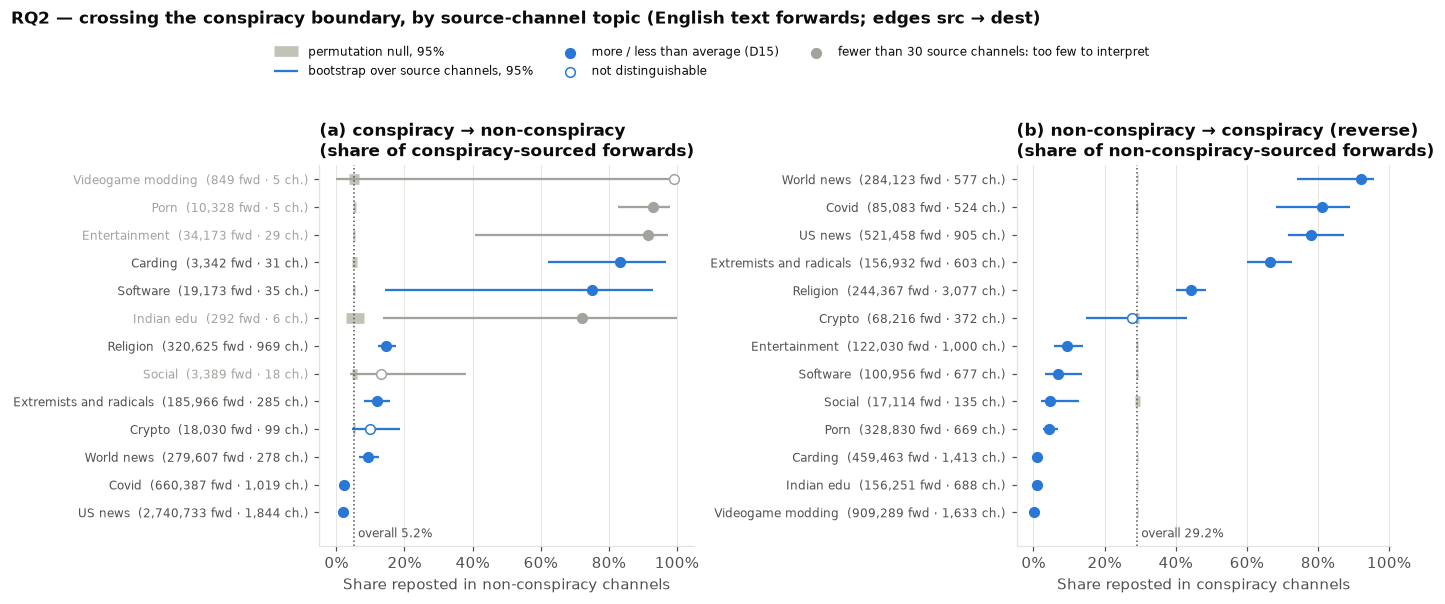

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
dotplot(axes[0], rq2, "(a) conspiracy → non-conspiracy\n(share of conspiracy-sourced forwards)", "Share reposted in non-conspiracy channels")
dotplot(axes[1], rq2r, "(b) non-conspiracy → conspiracy (reverse)\n(share of non-conspiracy-sourced forwards)", "Share reposted in conspiracy channels")
handles, labels = axes[0].get_legend_handles_labels()
fig.suptitle("RQ2 — crossing the conspiracy boundary, by source-channel topic (English text forwards; edges src → dest)",
             x=0.01, y=0.99, ha="left", fontsize=11, fontweight="bold")
fig.legend(handles, labels, loc="upper center", ncol=3, fontsize=8, bbox_to_anchor=(0.5, 0.95))
fig.tight_layout(rect=(0, 0, 1, 0.89))
plots.savefig(fig, "03_fig3_rq2", OUT)
plt.show()

## 4 · Numbers for the progress report

In [10]:
def verdicts(tab):
    more = tab[tab.verdict == "more"].sort_values("excess_pp", ascending=False)
    less = tab[tab.verdict == "less"].sort_values("excess_pp")
    f = lambda t: ", ".join(f"{a} ({r:.1%})" for a, r in zip(t.topic, t.rate)) or "none"
    return f"more than average: {f(more)}\n    less than average: {f(less)}"

print(f'''Interim results (topic = LDA topic of the SOURCE channel; English–English text forwards, n = {fw.n_text.sum():,}).
Source/destination channel topics: {same:.1%} of forwards stay within the same channel topic (expected {same_exp:.1%}), assortativity r = {r:.2f}.
RQ1: {rq1.attrs['overall_rate']:.1%} of forwards cross a community boundary ({rq1.attrs['events']:,} of {rq1.attrs['population']:,}).
    {verdicts(rq1)}
RQ2: {rq2.attrs['overall_rate']:.1%} of conspiracy-sourced forwards reach non-conspiracy channels ({rq2.attrs['events']:,} of {rq2.attrs['population']:,}).
    {verdicts(rq2)}
RQ2 reverse: {rq2r.attrs['overall_rate']:.1%} of non-conspiracy-sourced forwards are reposted by conspiracy channels ({rq2r.attrs['events']:,} of {rq2r.attrs['population']:,}).
    {verdicts(rq2r)}
Verdict rule: BH q < 0.05 (permutation over forwards) AND bootstrap 95% interval over source channels excludes the overall rate.''')

Interim results (topic = LDA topic of the SOURCE channel; English–English text forwards, n = 7,731,006).
Source/destination channel topics: 70.6% of forwards stay within the same channel topic (expected 23.0%), assortativity r = 0.62.
RQ1: 5.0% of forwards cross a community boundary (386,975 of 7,731,006).
    more than average: World news (13.8%), Covid (9.9%)
    less than average: Videogame modding (0.1%), Indian edu (0.3%), Carding (0.5%), Porn (1.5%), Extremists and radicals (3.5%)
RQ2: 5.2% of conspiracy-sourced forwards reach non-conspiracy channels (221,594 of 4,276,894).
    more than average: Porn (93.0%), Entertainment (91.4%), Carding (83.3%), Software (75.0%), Indian edu (72.3%), Religion (14.7%), Extremists and radicals (11.8%), World news (9.3%)
    less than average: US news (1.8%), Covid (2.2%)
RQ2 reverse: 29.2% of non-conspiracy-sourced forwards are reposted by conspiracy channels (1,009,879 of 3,454,112).
    more than average: World news (92.2%), Covid (81.2%), US 